In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

print(os.listdir('/content/drive/MyDrive'))

['Joint Entrance Examination (Main) | India', 'EAadhaar_0704140360011420240608121655_10062024152636 (1) (1).pdf', '10th.pdf', 'Nithin 2007.pdf', 'Gowtham .pdf', 'Untitled spreadsheet.gsheet', 'Electromagnetics assignment.pdf', 'ews (1).pdf', 'ews.pdf', 'batch 3 sports ', 'batch 3 sports 1', 'design assignment .pdf', 'Em assignment.pdf', 'Bank .pdf', 'SIH ppt.pdf', 'Nikhillll.pdf', 'Xerox.pdf', 'gsrr_1.pdf', 'gsrr_2.pdf', 'gsrr_3.pdf', 'gsrr_4.pdf', 'gsrr_5.pdf', 'gsrr_6.pdf', 'gsrr_7.pdf', 'gsrr_8.pdf', 'gsrr_9.pdf', 'gsrr_10.pdf', 'gsrr_11.pdf', 'gsrr_12.pdf', 'gsrr_13.pdf', 'gsrr_14.pdf', 'gsrr_15.pdf', 'Testimonial.pdf', 'Testimonial video', "Nithin's photo.jpg", 'What is meant by 3dB frequency??.gsheet', 'Colab Notebooks', 'Wafer Classification', 'analog lab 11.pdf', 'DSP hardware.pdf']


In [4]:
import os

dataset_path = '/content/drive/MyDrive/Wafer Classification/LSWMD.pkl'

print("Dataset exists:", os.path.exists(dataset_path))

Dataset exists: True


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Loading dataset...")

df = pd.read_pickle(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Loading dataset...
Dataset loaded successfully!
Dataset shape: (811457, 6)


In [6]:
import torch

print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [7]:
print("========== DATASET OVERVIEW ==========")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("Dataset size:", df.shape)

print("Column names:")
print(df.columns.tolist())

========== DATASET OVERVIEW ==========
Number of rows: 811457
Number of columns: 6
Dataset size: (811457, 6)
Column names:
['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']


In [8]:
print("========== DATASET INFORMATION ==========")

df.info()

========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   waferIndex      811457 non-null  float64
 4   trianTestLabel  811457 non-null  object 
 5   failureType     811457 non-null  object 
dtypes: float64(2), object(4)
memory usage: 37.1+ MB


In [9]:
print("========== MISSING VALUES ==========")

print(df.isnull().sum())

========== MISSING VALUES ==========
waferMap          0
dieSize           0
lotName           0
waferIndex        0
trianTestLabel    0
failureType       0
dtype: int64


In [10]:
print("========== STATISTICAL SUMMARY ==========")

print(df[['dieSize', 'waferIndex']].describe())

========== STATISTICAL SUMMARY ==========
             dieSize     waferIndex
count  811457.000000  811457.000000
mean     1840.998585      12.961207
std      2254.987374       7.207489
min         3.000000       1.000000
25%       710.000000       7.000000
50%       953.000000      13.000000
75%      1902.000000      19.000000
max     48099.000000      25.000000


In [11]:
def extract_label(x):
    while isinstance(x, (list, tuple, np.ndarray)):
        if len(x) == 0:
            return "Unknown"
        x = x[0]
    return str(x)

labels = df['failureType'].apply(extract_label)

print("========== DEFECT TYPE DISTRIBUTION ==========")
print(labels.value_counts())

========== DEFECT TYPE DISTRIBUTION ==========
failureType
Unknown      638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


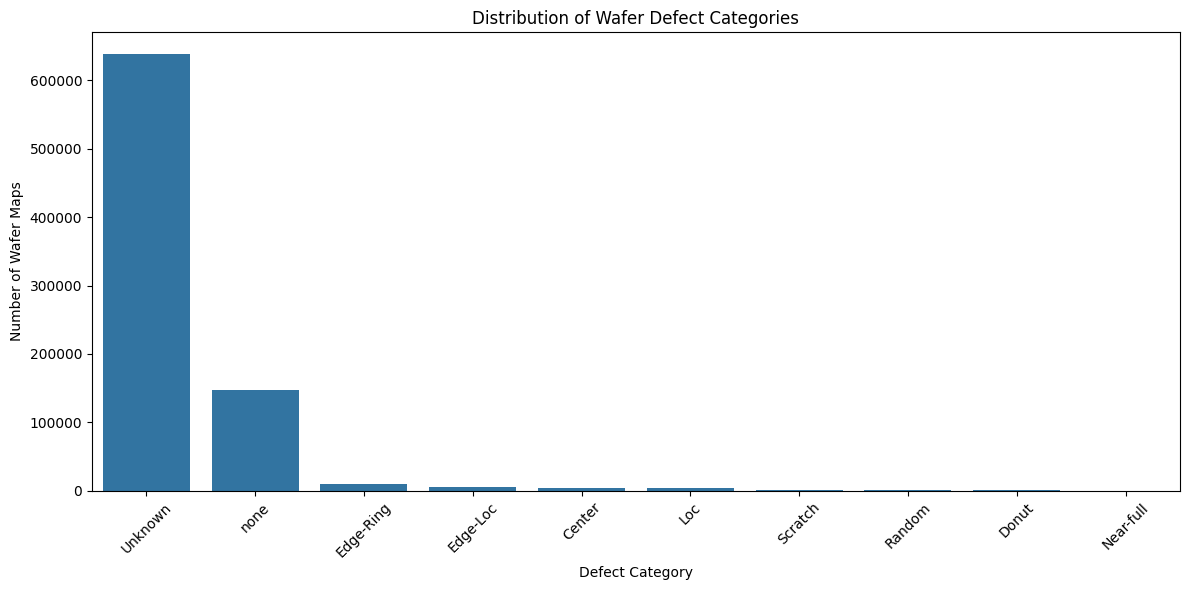

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.countplot(
    x=labels,
    order=labels.value_counts().index
)

plt.title("Distribution of Wafer Defect Categories")
plt.xlabel("Defect Category")
plt.ylabel("Number of Wafer Maps")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    os.path.join(eda_path, 'Distribution of Wafer Defect Categories.png'),
    dpi=300,
    bbox_inches='tight'
)


plt.show()

In [13]:
print("First 10 original failureType values:")

for i in range(10):
    print(i, repr(df['failureType'].iloc[i]))

print("\nType of first value:")
print(type(df['failureType'].iloc[0]))

First 10 original failureType values:
0 array([['none']], dtype='<U4')
1 array([['none']], dtype='<U4')
2 array([['none']], dtype='<U4')
3 array([['none']], dtype='<U4')
4 array([['none']], dtype='<U4')
5 array([['none']], dtype='<U4')
6 array([['none']], dtype='<U4')
7 array([['none']], dtype='<U4')
8 array([['none']], dtype='<U4')
9 array([['none']], dtype='<U4')

Type of first value:
<class 'numpy.ndarray'>


Wafer map shape: (45, 48)
Unique values: [0 1 2]


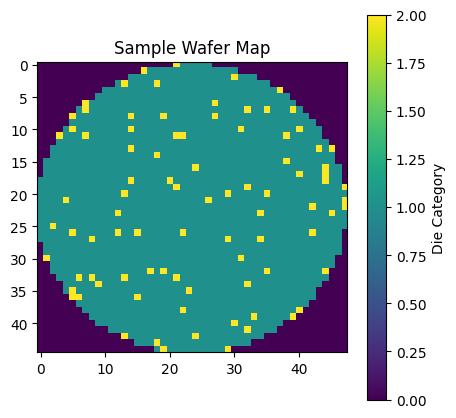

In [40]:
sample_map = df['waferMap'].iloc[0]

print("Wafer map shape:", sample_map.shape)
print("Unique values:", np.unique(sample_map))

plt.figure(figsize=(5, 5))
plt.imshow(sample_map, cmap='viridis')
plt.title("Sample Wafer Map")
plt.colorbar(label="Die Category")
plt.savefig(
    os.path.join(eda_path, 'Sample Wafer Map.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [15]:
def extract_label(x):
    arr = np.asarray(x).flatten()

    if arr.size == 0:
        return "Unknown"

    return str(arr[0])

labels = df['failureType'].apply(extract_label)

print("========== DEFECT DISTRIBUTION ==========")
print(labels.value_counts())

========== DEFECT DISTRIBUTION ==========
failureType
Unknown      638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


In [16]:
print("========== INVESTIGATING UNKNOWN LABELS ==========")

unknown_indices = labels[labels == "Unknown"].index[:10]

for i in unknown_indices:
    print("Index:", i)
    print("Original value:", repr(df['failureType'].iloc[i]))
    print("Array shape:", np.asarray(df['failureType'].iloc[i]).shape)
    print("-" * 50)

========== INVESTIGATING UNKNOWN LABELS ==========
Index: 35
Original value: array([], shape=(0, 0), dtype=float64)
Array shape: (0, 0)
--------------------------------------------------
Index: 45
Original value: array([], shape=(0, 0), dtype=float64)
Array shape: (0, 0)
--------------------------------------------------
Index: 69
Original value: array([], shape=(0, 0), dtype=float64)
Array shape: (0, 0)
--------------------------------------------------
Index: 120
Original value: array([], shape=(0, 0), dtype=float64)
Array shape: (0, 0)
--------------------------------------------------
Index: 158
Original value: array([], shape=(0, 0), dtype=float64)
Array shape: (0, 0)
--------------------------------------------------
Index: 159
Original value: array([], shape=(0, 0), dtype=float64)
Array shape: (0, 0)
--------------------------------------------------
Index: 161
Original value: array([], shape=(0, 0), dtype=float64)
Array shape: (0, 0)
--------------------------------------------

In [17]:
# ==========================================
# STEP 10: CREATE LABELLED DATASET
# ==========================================

# Keep only records with known labels
df_labeled = df[labels != "Unknown"].copy()

# Keep the corresponding labels
labels_labeled = labels[labels != "Unknown"].copy()

print("========== LABELLED DATASET ==========")

print("Original dataset size:", len(df))
print("Labelled dataset size:", len(df_labeled))
print("Unlabelled records removed:", len(df) - len(df_labeled))

print("\nDefect distribution:")
print(labels_labeled.value_counts())

print("\nNumber of classes:", labels_labeled.nunique())

========== LABELLED DATASET ==========
Original dataset size: 811457
Labelled dataset size: 172950
Unlabelled records removed: 638507

Defect distribution:
failureType
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

Number of classes: 9


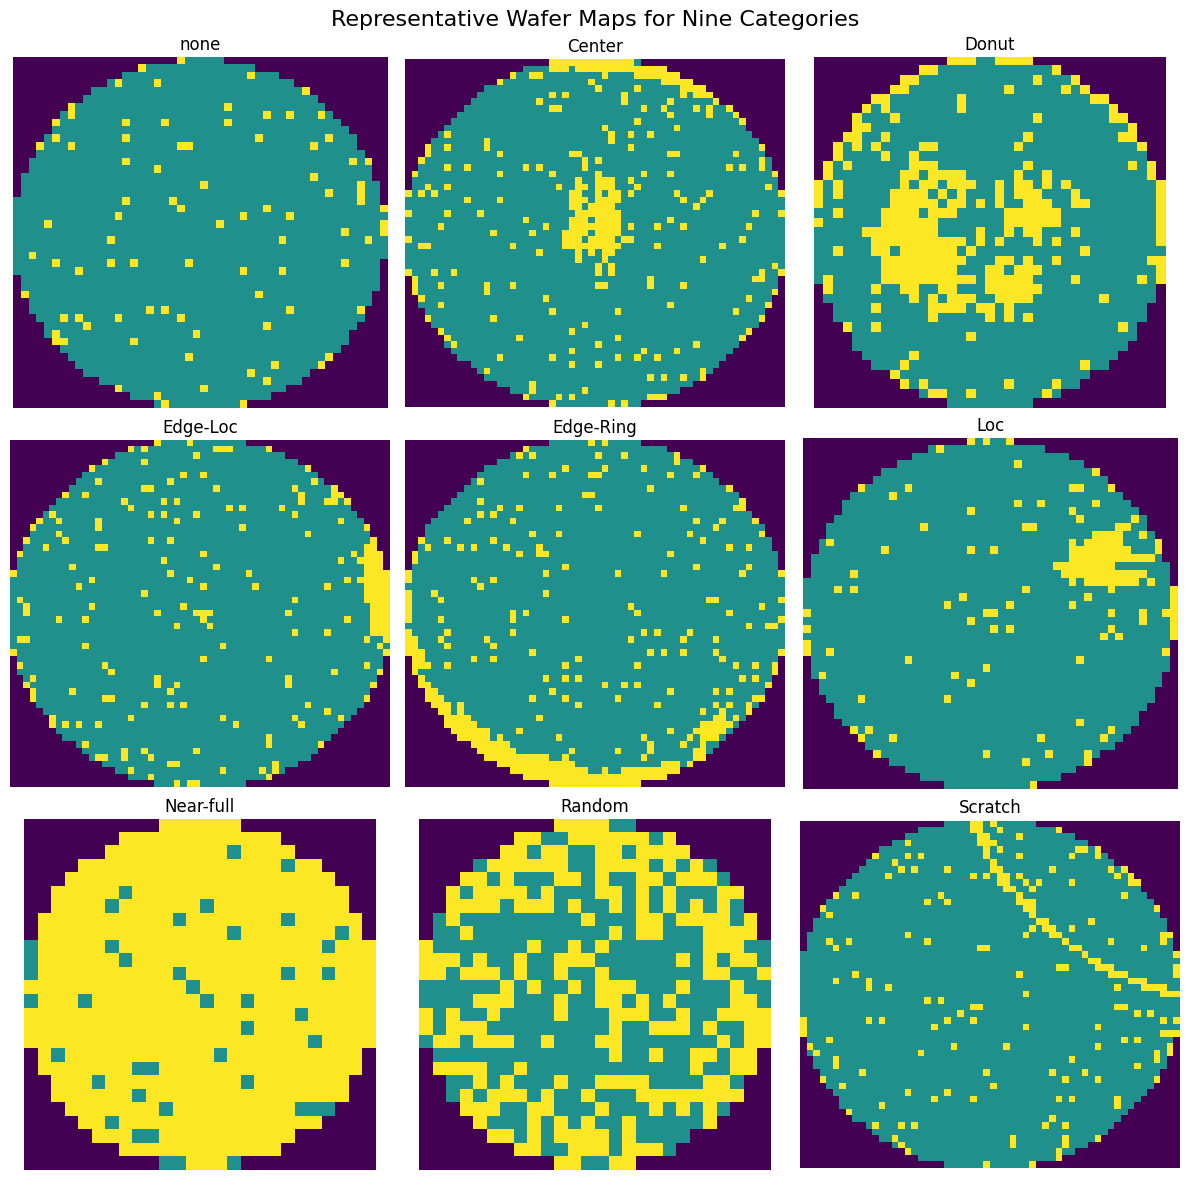

In [37]:
# ==========================================
# STEP 11: VISUALIZE ALL WAFER CATEGORIES
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

classes = [
    'none', 'Center', 'Donut', 'Edge-Loc',
    'Edge-Ring', 'Loc', 'Near-full',
    'Random', 'Scratch'
]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, category in zip(axes.flatten(), classes):

    # Find the first wafer belonging to this category
    idx = labels_labeled[labels_labeled == category].index[0]

    wafer = df_labeled.loc[idx, 'waferMap']

    ax.imshow(wafer, cmap='viridis')
    ax.set_title(category)
    ax.axis('off')

plt.suptitle("Representative Wafer Maps for Nine Categories",
             fontsize=16)

plt.tight_layout()
plt.savefig(
    os.path.join(eda_path, 'class_distribution.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [19]:
# ==========================================
# STEP 12: WAFER MAP DIMENSION ANALYSIS
# ==========================================

print("========== WAFER MAP DIMENSIONS ==========")

print("\nFirst 10 wafer map shapes:")

for i in range(10):
    wafer = df_labeled.iloc[i]['waferMap']
    print(i, wafer.shape)

print("\nUnique values in a sample wafer map:")

sample_map = df_labeled.iloc[0]['waferMap']

print(np.unique(sample_map))

========== WAFER MAP DIMENSIONS ==========

First 10 wafer map shapes:
0 (45, 48)
1 (45, 48)
2 (45, 48)
3 (45, 48)
4 (45, 48)
5 (45, 48)
6 (45, 48)
7 (45, 48)
8 (45, 48)
9 (45, 48)

Unique values in a sample wafer map:
[0 1 2]


In [20]:
# ==========================================
# STEP 13: CHECK ALL WAFER MAP DIMENSIONS
# ==========================================

from collections import Counter

shape_counts = Counter(
    wafer.shape for wafer in df_labeled['waferMap']
)

print("========== WAFER MAP SHAPE DISTRIBUTION ==========")

print("Number of unique shapes:", len(shape_counts))

print("\nMost common wafer map shapes:")

for shape, count in shape_counts.most_common(15):
    print(shape, ":", count)

========== WAFER MAP SHAPE DISTRIBUTION ==========
Number of unique shapes: 346

Most common wafer map shapes:
(25, 27) : 18781
(26, 26) : 14366
(30, 34) : 12400
(29, 26) : 11751
(27, 25) : 10682
(39, 37) : 10173
(33, 29) : 8125
(42, 44) : 6724
(44, 41) : 6134
(41, 33) : 5091
(35, 31) : 4331
(25, 26) : 4174
(41, 38) : 4152
(33, 37) : 3729
(29, 27) : 2872


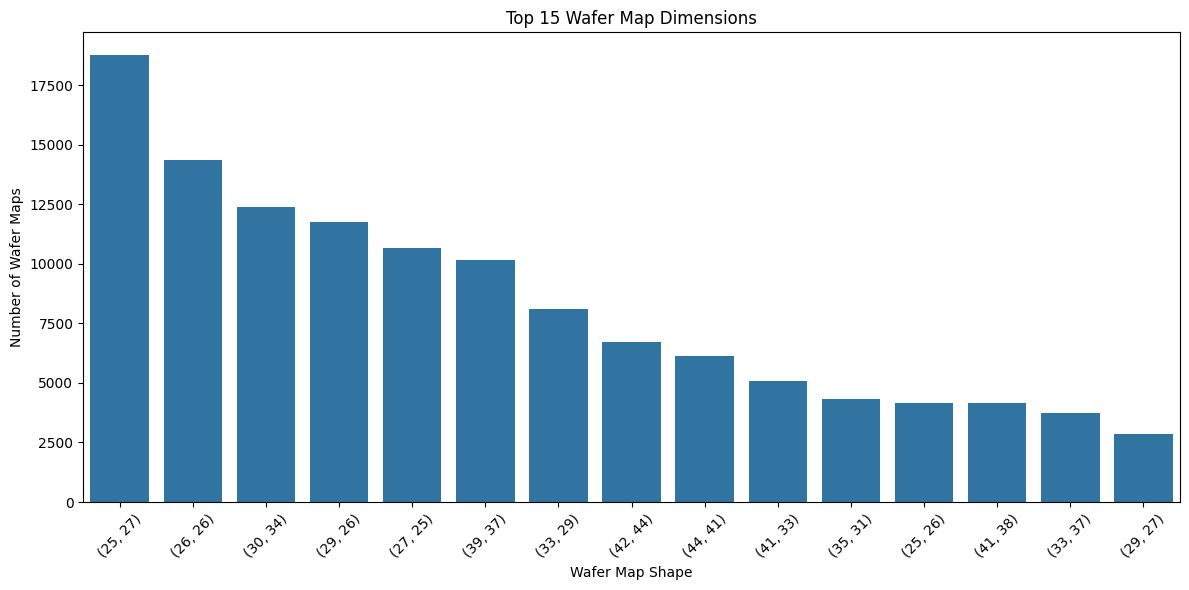

In [41]:
# ==========================================
# STEP 14: WAFER MAP DIMENSION ANALYSIS
# ==========================================

shape_df = pd.DataFrame(
    [(str(shape), count) for shape, count in shape_counts.items()],
    columns=['Shape', 'Count']
)

shape_df = shape_df.sort_values(
    by='Count', ascending=False
).head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=shape_df,
    x='Shape',
    y='Count'
)

plt.title("Top 15 Wafer Map Dimensions")
plt.xlabel("Wafer Map Shape")
plt.ylabel("Number of Wafer Maps")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    os.path.join(eda_path, 'Top 15 Wafer Map Dimensions.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [22]:
# ==========================================
# STEP 15: PASSING AND FAILING DIE ANALYSIS
# ==========================================

def count_dies(wafer):
    values, counts = np.unique(wafer, return_counts=True)
    return dict(zip(values, counts))

# Select one sample from each class
classes = labels_labeled.unique()

for category in classes:

    idx = labels_labeled[labels_labeled == category].index[0]

    wafer = df_labeled.loc[idx, 'waferMap']

    counts = count_dies(wafer)

    print("\nDefect Category:", category)
    print("Background dies (0):", counts.get(0, 0))
    print("Passing dies (1):", counts.get(1, 0))
    print("Failing dies (2):", counts.get(2, 0))


Defect Category: none
Background dies (0): 477
Passing dies (1): 1595
Failing dies (2): 88

Defect Category: Loc
Background dies (0): 477
Passing dies (1): 1537
Failing dies (2): 146

Defect Category: Edge-Loc
Background dies (0): 614
Passing dies (1): 2241
Failing dies (2): 219

Defect Category: Center
Background dies (0): 614
Passing dies (1): 2145
Failing dies (2): 315

Defect Category: Edge-Ring
Background dies (0): 614
Passing dies (1): 2125
Failing dies (2): 335

Defect Category: Scratch
Background dies (0): 614
Passing dies (1): 2254
Failing dies (2): 206

Defect Category: Random
Background dies (0): 143
Passing dies (1): 291
Failing dies (2): 242

Defect Category: Near-full
Background dies (0): 143
Passing dies (1): 43
Failing dies (2): 490

Defect Category: Donut
Background dies (0): 278
Passing dies (1): 810
Failing dies (2): 281


In [23]:
# ==========================================
# STEP 16: CLASS-WISE FAILING DIE ANALYSIS
# ==========================================

class_results = []

for category in classes:

    indices = labels_labeled[labels_labeled == category].index

    total_passing = 0
    total_failing = 0

    for idx in indices:

        wafer = df_labeled.loc[idx, 'waferMap']

        total_passing += np.count_nonzero(wafer == 1)
        total_failing += np.count_nonzero(wafer == 2)

    total_dies = total_passing + total_failing

    failing_percentage = (
        total_failing / total_dies * 100
        if total_dies > 0 else 0
    )

    class_results.append({
        'Defect Category': category,
        'Total Passing Dies': total_passing,
        'Total Failing Dies': total_failing,
        'Failing Die Percentage': failing_percentage
    })

class_summary = pd.DataFrame(class_results)

print("========== CLASS-WISE FAILING DIE ANALYSIS ==========")

print(class_summary.to_string(index=False))

========== CLASS-WISE FAILING DIE ANALYSIS ==========
Defect Category  Total Passing Dies  Total Failing Dies  Failing Die Percentage
           none           123659750            12180070                8.966495
            Loc             4323564              530656               10.931849
       Edge-Loc             5106194              970907               15.976483
         Center             3255286              732198               18.362406
      Edge-Ring            22244272             2934194               11.653585
        Scratch             2244055              154388                6.437009
         Random              555690              475955               46.135541
      Near-full               15148              107249               87.623880
          Donut              544316              220197               28.802257


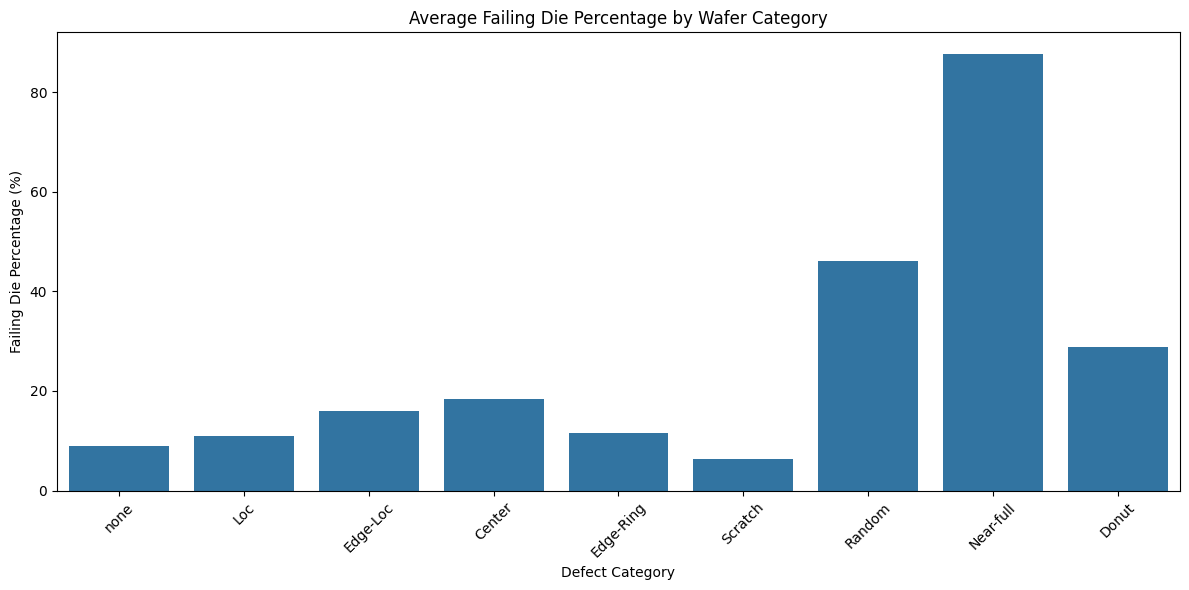

In [42]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=class_summary,
    x='Defect Category',
    y='Failing Die Percentage'
)

plt.title("Average Failing Die Percentage by Wafer Category")
plt.xlabel("Defect Category")
plt.ylabel("Failing Die Percentage (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    os.path.join(eda_path, 'Falling Die Percentage.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [25]:
# ==========================================
# STEP 17: CLASS IMBALANCE ANALYSIS
# ==========================================

class_counts = labels_labeled.value_counts()

class_distribution = pd.DataFrame({
    'Class': class_counts.index,
    'Number of Samples': class_counts.values,
    'Percentage': (
        class_counts.values / len(labels_labeled)
    ) * 100
})

print("========== CLASS DISTRIBUTION ==========")

print(
    class_distribution.to_string(
        index=False,
        formatters={'Percentage': '{:.2f}%'.format}
    )
)

print("\nTotal labelled samples:", len(labels_labeled))
print("Total classes:", len(class_counts))

========== CLASS DISTRIBUTION ==========
    Class  Number of Samples Percentage
     none             147431     85.24%
Edge-Ring               9680      5.60%
 Edge-Loc               5189      3.00%
   Center               4294      2.48%
      Loc               3593      2.08%
  Scratch               1193      0.69%
   Random                866      0.50%
    Donut                555      0.32%
Near-full                149      0.09%

Total labelled samples: 172950
Total classes: 9


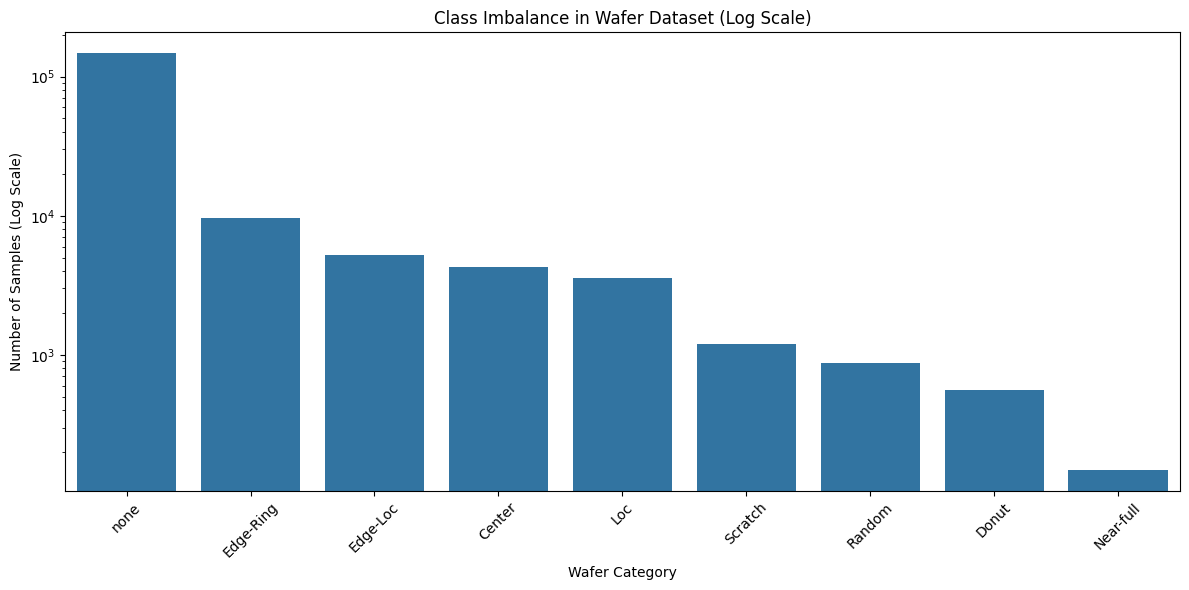

In [43]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=class_distribution,
    x='Class',
    y='Number of Samples'
)

plt.yscale('log')

plt.title("Class Imbalance in Wafer Dataset (Log Scale)")
plt.xlabel("Wafer Category")
plt.ylabel("Number of Samples (Log Scale)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    os.path.join(eda_path, 'class_imbalance in Wafer Dataset.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [27]:
# ==========================================
# STEP 19: TRAIN / VALIDATION / TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

# Convert labels into numerical class IDs
class_names = sorted(labels_labeled.unique())

class_to_id = {
    name: idx for idx, name in enumerate(class_names)
}

y = labels_labeled.map(class_to_id).values

# First split: 70% training, 30% temporary
train_indices, temp_indices = train_test_split(
    np.arange(len(y)),
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=y[temp_indices]
)

print("========== DATASET SPLIT ==========")

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Testing samples:", len(test_indices))

print("\nClass names and IDs:")
print(class_to_id)

========== DATASET SPLIT ==========
Training samples: 121065
Validation samples: 25942
Testing samples: 25943

Class names and IDs:
{'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Near-full': 5, 'Random': 6, 'Scratch': 7, 'none': 8}


In [28]:
# ==========================================
# STEP 20: VERIFY STRATIFIED SPLIT
# ==========================================

for name, indices in [
    ("Training", train_indices),
    ("Validation", val_indices),
    ("Testing", test_indices)
]:

    print("\n", name, "distribution:")

    print(
        pd.Series(y[indices])
        .value_counts()
        .sort_index()
        .rename(index={v: k for k, v in class_to_id.items()})
    )


 Training distribution:
Center         3006
Donut           389
Edge-Loc       3632
Edge-Ring      6776
Loc            2515
Near-full       104
Random          606
Scratch         835
none         103202
Name: count, dtype: int64

 Validation distribution:
Center         644
Donut           83
Edge-Loc       778
Edge-Ring     1452
Loc            539
Near-full       23
Random         130
Scratch        179
none         22114
Name: count, dtype: int64

 Testing distribution:
Center         644
Donut           83
Edge-Loc       779
Edge-Ring     1452
Loc            539
Near-full       22
Random         130
Scratch        179
none         22115
Name: count, dtype: int64


In [29]:
# ==========================================
# STEP 21: WAFER MAP PREPROCESSING
# ==========================================

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def preprocess_wafer(wafer, target_size=64):

    height, width = wafer.shape

    # Calculate scale while preserving aspect ratio
    scale = min(target_size / height, target_size / width)

    new_height = max(1, round(height * scale))
    new_width = max(1, round(width * scale))

    # Resize using nearest-neighbour interpolation
    image = Image.fromarray(wafer.astype(np.uint8))

    resized = image.resize(
        (new_width, new_height),
        Image.Resampling.NEAREST
    )

    resized = np.array(resized)

    # Create a zero-filled 64 x 64 canvas
    canvas = np.zeros(
        (target_size, target_size),
        dtype=np.uint8
    )

    # Calculate padding
    top = (target_size - new_height) // 2
    left = (target_size - new_width) // 2

    # Place resized wafer in the centre
    canvas[
        top:top + new_height,
        left:left + new_width
    ] = resized

    return canvas


# Test on one wafer
sample_wafer = df_labeled.iloc[0]['waferMap']

processed_wafer = preprocess_wafer(sample_wafer)

print("Original shape:", sample_wafer.shape)
print("Processed shape:", processed_wafer.shape)
print("Original values:", np.unique(sample_wafer))
print("Processed values:", np.unique(processed_wafer))

Original shape: (45, 48)
Processed shape: (64, 64)
Original values: [0 1 2]
Processed values: [0 1 2]


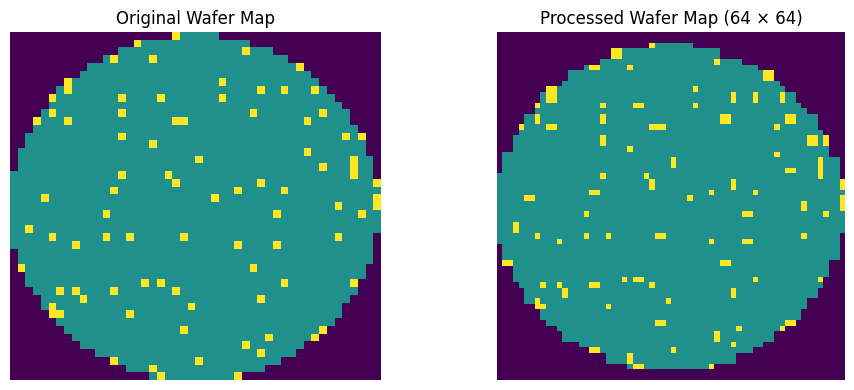

In [44]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_wafer, cmap='viridis', vmin=0, vmax=2)
plt.title("Original Wafer Map")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(processed_wafer, cmap='viridis', vmin=0, vmax=2)
plt.title("Processed Wafer Map (64 × 64)")
plt.axis('off')

plt.tight_layout()
plt.savefig(
    os.path.join(eda_path, 'Original vs Processed Wafer Map.png'),
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [31]:
# ==========================================
# STEP 23: PREPROCESS ALL WAFER MAPS
# ==========================================

def preprocess_dataset(indices):

    images = []

    for i, idx in enumerate(indices):

        wafer = df_labeled.loc[
            labels_labeled.index[idx], 'waferMap'
        ]

        processed = preprocess_wafer(wafer)

        images.append(processed)

        if (i + 1) % 10000 == 0:
            print("Processed:", i + 1, "/", len(indices))

    return np.stack(images)


print("Processing training data...")
X_train = preprocess_dataset(train_indices)

print("\nProcessing validation data...")
X_val = preprocess_dataset(val_indices)

print("\nProcessing testing data...")
X_test = preprocess_dataset(test_indices)


print("\n========== PREPROCESSING COMPLETE ==========")

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("Data type:", X_train.dtype)

Processing training data...
Processed: 10000 / 121065
Processed: 20000 / 121065
Processed: 30000 / 121065
Processed: 40000 / 121065
Processed: 50000 / 121065
Processed: 60000 / 121065
Processed: 70000 / 121065
Processed: 80000 / 121065
Processed: 90000 / 121065
Processed: 100000 / 121065
Processed: 110000 / 121065
Processed: 120000 / 121065

Processing validation data...
Processed: 10000 / 25942
Processed: 20000 / 25942

Processing testing data...
Processed: 10000 / 25943
Processed: 20000 / 25943

========== PREPROCESSING COMPLETE ==========
Training shape: (121065, 64, 64)
Validation shape: (25942, 64, 64)
Testing shape: (25943, 64, 64)
Data type: uint8


In [32]:
# ==========================================
# STEP 24: PREPARE CLASS LABELS
# ==========================================

y_train = y[train_indices]
y_val = y[val_indices]
y_test = y[test_indices]

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

print("\nClass mapping:")
print(class_to_id)

Training labels: (121065,)
Validation labels: (25942,)
Testing labels: (25943,)

Class mapping:
{'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Near-full': 5, 'Random': 6, 'Scratch': 7, 'none': 8}


In [33]:
# ==========================================
# STEP 25: CALCULATE CLASS WEIGHTS
# ==========================================

from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

print("========== CLASS WEIGHTS ==========")

for class_id, weight in enumerate(class_weights):
    print(
        class_names[class_id],
        ":",
        round(weight, 4)
    )

========== CLASS WEIGHTS ==========
Center : 4.4749
Donut : 34.5801
Edge-Loc : 3.7037
Edge-Ring : 1.9852
Loc : 5.3486
Near-full : 129.3429
Random : 22.1975
Scratch : 16.1098
none : 0.1303


In [34]:
from google.colab import drive
drive.mount('/content/drive')

import os

project_path = '/content/drive/MyDrive/Wafer Classification'
eda_path = os.path.join(project_path, 'results', 'eda')

os.makedirs(eda_path, exist_ok=True)

print("EDA results folder:", eda_path)
print("Folder exists:", os.path.exists(eda_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EDA results folder: /content/drive/MyDrive/Wafer Classification/results/eda
Folder exists: True


In [46]:
# Extract lot names for each dataset split

train_lots = set(
    df_labeled.iloc[train_indices]['lotName'].dropna()
)

val_lots = set(
    df_labeled.iloc[val_indices]['lotName'].dropna()
)

test_lots = set(
    df_labeled.iloc[test_indices]['lotName'].dropna()
)

# Check overlapping lots

print("Train-Val overlap:", len(train_lots & val_lots))

print("Train-Test overlap:", len(train_lots & test_lots))

print("Val-Test overlap:", len(val_lots & test_lots))
# Check missing lot names
print("Missing lot names:",
      df_labeled['lotName'].isna().sum())

# Count unique production lots
print("Unique production lots:",
      df_labeled['lotName'].nunique())

# Check number of samples per lot
lot_counts = df_labeled['lotName'].value_counts()

print("\nTop 10 lots by number of wafers:")
print(lot_counts.head(10))

print("\nLot count statistics:")
print(lot_counts.describe())

Train-Val overlap: 7356
Train-Test overlap: 7385
Val-Test overlap: 6926
Missing lot names: 0
Unique production lots: 10762

Top 10 lots by number of wafers:
lotName
lot47513    25
lot47542    25
lot1        25
lot47512    25
lot47511    25
lot4        25
lot47510    25
lot6        25
lot47541    25
lot42079    25
Name: count, dtype: int64

Lot count statistics:
count    10762.000000
mean        16.070433
std         10.579723
min          1.000000
25%          2.000000
50%         23.000000
75%         25.000000
max         25.000000
Name: count, dtype: float64


In [47]:
from sklearn.model_selection import GroupShuffleSplit

# Production lot names
groups = df_labeled['lotName'].astype(str).to_numpy()

# First split: 70% training, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(np.arange(len(y)), y, groups)
)

# Second split: 15% validation, 15% testing
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_temp_idx, test_temp_idx = next(
    split2.split(
        temp_idx,
        y[temp_idx],
        groups[temp_idx]
    )
)

val_idx = temp_idx[val_temp_idx]
test_idx = temp_idx[test_temp_idx]

# Check dataset sizes
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))

print("\nTotal samples:",
      len(train_idx) + len(val_idx) + len(test_idx))

Training samples: 120979
Validation samples: 26116
Testing samples: 25855

Total samples: 172950


In [48]:
train_lots = set(groups[train_idx])
val_lots = set(groups[val_idx])
test_lots = set(groups[test_idx])

print("Train-Val overlap:", len(train_lots & val_lots))
print("Train-Test overlap:", len(train_lots & test_lots))
print("Val-Test overlap:", len(val_lots & test_lots))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [49]:
# Check dataset sizes
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))

print("\nTotal samples:",
      len(train_idx) + len(val_idx) + len(test_idx))

Training samples: 120979
Validation samples: 26116
Testing samples: 25855

Total samples: 172950


In [50]:
class_names = sorted(labels_labeled.unique())

print("Training class distribution:")
print(pd.Series(y[train_idx]).map(
    {v: k for k, v in class_to_id.items()}
).value_counts().reindex(class_names, fill_value=0))

print("\nValidation class distribution:")
print(pd.Series(y[val_idx]).map(
    {v: k for k, v in class_to_id.items()}
).value_counts().reindex(class_names, fill_value=0))

print("\nTesting class distribution:")
print(pd.Series(y[test_idx]).map(
    {v: k for k, v in class_to_id.items()}
).value_counts().reindex(class_names, fill_value=0))

Training class distribution:
Center         3008
Donut           366
Edge-Loc       3630
Edge-Ring      6871
Loc            2411
Near-full       107
Random          614
Scratch         871
none         103101
Name: count, dtype: int64

Validation class distribution:
Center         683
Donut          106
Edge-Loc       787
Edge-Ring     1377
Loc            606
Near-full       27
Random         121
Scratch        145
none         22264
Name: count, dtype: int64

Testing class distribution:
Center         603
Donut           83
Edge-Loc       772
Edge-Ring     1432
Loc            576
Near-full       15
Random         131
Scratch        177
none         22066
Name: count, dtype: int64


In [51]:
import os
import pandas as pd

# Google Drive folder
split_path = '/content/drive/MyDrive/Wafer Classification/splits'

os.makedirs(split_path, exist_ok=True)

# Convert class IDs back to class names
id_to_class = {v: k for k, v in class_to_id.items()}

# Function to create split DataFrame
def create_split_dataframe(indices):

    return pd.DataFrame({
        'row_index': df_labeled.index.to_numpy()[indices],
        'lotName': groups[indices],
        'label_id': y[indices],
        'label': [id_to_class[i] for i in y[indices]]
    })

# Create three split DataFrames
train_df = create_split_dataframe(train_idx)
val_df = create_split_dataframe(val_idx)
test_df = create_split_dataframe(test_idx)

# Save CSV files
train_df.to_csv(os.path.join(split_path, 'train.csv'), index=False)
val_df.to_csv(os.path.join(split_path, 'validation.csv'), index=False)
test_df.to_csv(os.path.join(split_path, 'test.csv'), index=False)

print("All dataset splits saved successfully!")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

All dataset splits saved successfully!
Training: 120979
Validation: 26116
Testing: 25855


In [52]:
# Preprocess using the new lot-wise indices

X_train = preprocess_dataset(train_idx)
X_val = preprocess_dataset(val_idx)
X_test = preprocess_dataset(test_idx)

print("Preprocessing completed!")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Processed: 10000 / 120979
Processed: 20000 / 120979
Processed: 30000 / 120979
Processed: 40000 / 120979
Processed: 50000 / 120979
Processed: 60000 / 120979
Processed: 70000 / 120979
Processed: 80000 / 120979
Processed: 90000 / 120979
Processed: 100000 / 120979
Processed: 110000 / 120979
Processed: 120000 / 120979
Processed: 10000 / 26116
Processed: 20000 / 26116
Processed: 10000 / 25855
Processed: 20000 / 25855
Preprocessing completed!
Training: (120979, 64, 64)
Validation: (26116, 64, 64)
Testing: (25855, 64, 64)


In [53]:
y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

Training labels: (120979,)
Validation labels: (26116,)
Testing labels: (25855,)


In [54]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

print("Updated class weights:")

for name, weight in zip(class_names, class_weights):
    print(f"{name}: {weight:.4f}")

Updated class weights:
Center: 4.4688
Donut: 36.7271
Edge-Loc: 3.7031
Edge-Ring: 1.9564
Loc: 5.5753
Near-full: 125.6272
Random: 21.8927
Scratch: 15.4330
none: 0.1304


In [55]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [56]:
# Import PyTorch Dataset class
# Dataset allows us to load images and labels individually.

import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader


# Custom Dataset class for Semiconductor Wafer Classification
class WaferDataset(Dataset):

    def __init__(self, images, labels):
        # Store the preprocessed wafer images and corresponding labels
        self.images = images
        self.labels = labels

    def __len__(self):
        # Return the total number of wafer images
        return len(self.images)

    def __getitem__(self, idx):
        # Retrieve one wafer map using its index
        image = self.images[idx]

        # Convert categorical wafer values (0, 1, 2)
        # into three separate one-hot encoded channels
        image = torch.tensor(image, dtype=torch.long)

        image = torch.nn.functional.one_hot(
            image, num_classes=3
        )

        # Change dimensions from (64, 64, 3) to (3, 64, 64)
        # PyTorch CNN models expect channels first
        image = image.permute(2, 0, 1).float()

        # Retrieve the corresponding class label
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        # Return the image and its label
        return image, label


print("WaferDataset class created successfully!")

WaferDataset class created successfully!


In [57]:
# Create separate PyTorch Dataset objects
# for training, validation and testing.

train_dataset = WaferDataset(X_train, y_train)
val_dataset = WaferDataset(X_val, y_val)
test_dataset = WaferDataset(X_test, y_test)

# Display the number of samples in each Dataset
print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 120979
Validation dataset: 26116
Testing dataset: 25855


In [58]:
# Import DataLoader to load wafer images in batches
from torch.utils.data import DataLoader

# Define the batch size
# The model will process 128 wafer images in one iteration
BATCH_SIZE = 128

# Create DataLoader for training
# shuffle=True randomly changes the sample order in every epoch
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

# Create DataLoader for validation
# shuffle=False preserves the original order
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Create DataLoader for testing
# Testing data is not shuffled
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Display the number of batches in each DataLoader
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 946
Validation batches: 205
Testing batches: 202


In [59]:
# Get one batch of images and labels from the training DataLoader
images, labels = next(iter(train_loader))

# Display the shapes and data types
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("Unique pixel values:", torch.unique(images))
print("Unique class labels:", torch.unique(labels))

Image batch shape: torch.Size([128, 3, 64, 64])
Label batch shape: torch.Size([128])
Image data type: torch.float32
Label data type: torch.int64
Unique pixel values: tensor([0., 1.])
Unique class labels: tensor([0, 1, 2, 3, 4, 5, 6, 8])


In [60]:
# ==========================================
# CUSTOM CNN ARCHITECTURE
# Semiconductor Wafer Pattern Classification
# ==========================================

import torch
import torch.nn as nn


# Define the Custom CNN model
class CustomCNN(nn.Module):

    def __init__(self, num_classes=9):
        super(CustomCNN, self).__init__()

        # Convolution Block 1
        # Extract basic patterns and edges from wafer maps
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Convolution Block 2
        # Learn more complex wafer defect patterns
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Convolution Block 3
        # Extract higher-level spatial features
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Convert feature maps into a fixed-size representation
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Fully connected classification layer
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # Pass input through the three convolution blocks
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)

        # Apply global average pooling
        x = self.global_pool(x)

        # Predict the wafer defect class
        x = self.classifier(x)

        return x


# Initialize the Custom CNN
model = CustomCNN(num_classes=9)

# Select GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Custom CNN model created successfully!")
print("Using device:", device)

Custom CNN model created successfully!
Using device: cuda


In [61]:
# ==========================================
# VERIFY CUSTOM CNN ARCHITECTURE
# ==========================================

# Create a sample input with the same shape as our DataLoader batch
dummy_input = torch.randn(1, 3, 64, 64).to(device)

# Pass the sample input through the model
with torch.no_grad():
    output = model(dummy_input)

# Display input and output dimensions
print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

# Count total trainable parameters
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Trainable parameters:", total_params)

Input shape: torch.Size([1, 3, 64, 64])
Output shape: torch.Size([1, 9])
Trainable parameters: 94857


In [62]:
# ==========================================
# CONFIGURE LOSS FUNCTION AND OPTIMIZER
# ==========================================

# Convert the calculated class weights into a PyTorch tensor
# The weights help the model pay more attention to minority classes

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)


# Define weighted Cross Entropy Loss
# Higher weights penalize incorrect predictions on rare classes more
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)


# Define Adam optimizer
# It updates the CNN parameters during training
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


# Display the training configuration
print("Loss function:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", 0.001)
print("Class weights:", class_weights_tensor)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001
Class weights: tensor([  4.4688,  36.7271,   3.7031,   1.9564,   5.5753, 125.6272,  21.8927,
         15.4330,   0.1304], device='cuda:0')


In [63]:
# ==========================================
# TEST LOSS FUNCTION
# ==========================================

# Take one batch from the training DataLoader
images, labels = next(iter(train_loader))

# Move images and labels to the GPU
images = images.to(device)
labels = labels.to(device)

# Generate predictions using the CNN
outputs = model(images)

# Calculate weighted classification loss
loss = criterion(outputs, labels)

# Display the output dimensions and loss
print("Prediction shape:", outputs.shape)
print("Label shape:", labels.shape)
print("Initial loss:", loss.item())

Prediction shape: torch.Size([128, 9])
Label shape: torch.Size([128])
Initial loss: 3.0250422954559326


In [64]:
# ==========================================
# TRAINING AND VALIDATION FUNCTIONS
# ==========================================

def train_one_epoch(model, loader, criterion, optimizer, device):

    # Set model to training mode
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    # Process training data batch by batch
    for images, labels in loader:

        # Move images and labels to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients from previous iteration
        optimizer.zero_grad()

        # Forward pass: generate predictions
        outputs = model(images)

        # Calculate classification loss
        loss = criterion(outputs, labels)

        # Backward pass: calculate gradients
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Accumulate loss
        total_loss += loss.item() * images.size(0)

        # Calculate number of correct predictions
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    # Calculate average loss and accuracy
    epoch_loss = total_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):

    # Set model to evaluation mode
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    # Disable gradient calculation during validation
    with torch.no_grad():

        for images, labels in loader:

            # Move images and labels to GPU
            images = images.to(device)
            labels = labels.to(device)

            # Generate predictions
            outputs = model(images)

            # Calculate validation loss
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            # Calculate correct predictions
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    # Calculate average validation loss and accuracy
    epoch_loss = total_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


print("Training and validation functions created successfully!")

Training and validation functions created successfully!


In [65]:
# ==========================================
# TRAINING CONFIGURATION
# ==========================================

# Maximum number of training epochs
NUM_EPOCHS = 20

# Number of epochs to wait for validation loss improvement
PATIENCE = 5

# Minimum improvement required in validation loss
MIN_DELTA = 0.001

# Create folder to save model checkpoints
import os

checkpoint_path = '/content/drive/MyDrive/Wafer Classification/checkpoints'
os.makedirs(checkpoint_path, exist_ok=True)

# Initialize lists to record training history
history = {
    'train_loss': [],
    'val_loss': [],
    'train_accuracy': [],
    'val_accuracy': []
}

# Track the best validation loss
best_val_loss = float('inf')

# Track early stopping
epochs_without_improvement = 0

print("Training configuration completed!")

Training configuration completed!


In [66]:
# ==========================================
# CUSTOM CNN TRAINING LOOP
# ==========================================

for epoch in range(NUM_EPOCHS):

    # Train the model for one epoch
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Evaluate the model on validation data
    val_loss, val_acc = validate_one_epoch(
        model, val_loader, criterion, device
    )

    # Store metrics for plotting later
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_accuracy'].append(train_acc)
    history['val_accuracy'].append(val_acc)

    # Display epoch results
    print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_acc:.4f}")

    # Save checkpoint whenever validation loss improves
    if val_loss < best_val_loss - MIN_DELTA:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            model.state_dict(),
            os.path.join(checkpoint_path, 'custom_cnn.pth')
        )

        print("Best model saved!")

    else:
        epochs_without_improvement += 1

    # Stop if validation loss has not improved for PATIENCE epochs
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered!")
        break

print("\nCustom CNN training completed!")


Epoch [1/20]
Train Loss: 1.2242 | Train Accuracy: 0.6570
Val Loss:   1.2880 | Val Accuracy:   0.4377
Best model saved!

Epoch [2/20]
Train Loss: 0.9677 | Train Accuracy: 0.7567
Val Loss:   1.0792 | Val Accuracy:   0.7186
Best model saved!

Epoch [3/20]
Train Loss: 0.8625 | Train Accuracy: 0.7809
Val Loss:   0.9867 | Val Accuracy:   0.9225
Best model saved!

Epoch [4/20]
Train Loss: 0.7861 | Train Accuracy: 0.8159
Val Loss:   0.9139 | Val Accuracy:   0.9144
Best model saved!

Epoch [5/20]
Train Loss: 0.7281 | Train Accuracy: 0.8305
Val Loss:   0.8488 | Val Accuracy:   0.8453
Best model saved!

Epoch [6/20]
Train Loss: 0.6776 | Train Accuracy: 0.8456
Val Loss:   0.9426 | Val Accuracy:   0.7493

Epoch [7/20]
Train Loss: 0.6614 | Train Accuracy: 0.8564
Val Loss:   1.0097 | Val Accuracy:   0.7672

Epoch [8/20]
Train Loss: 0.6445 | Train Accuracy: 0.8579
Val Loss:   0.7915 | Val Accuracy:   0.8800
Best model saved!

Epoch [9/20]
Train Loss: 0.5864 | Train Accuracy: 0.8735
Val Loss:   0.8375

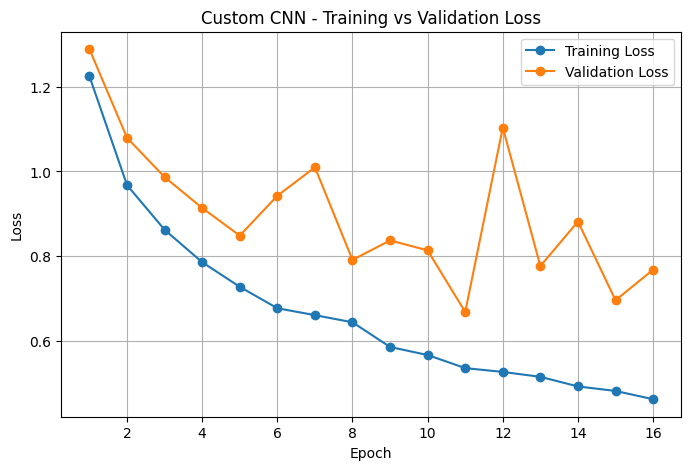

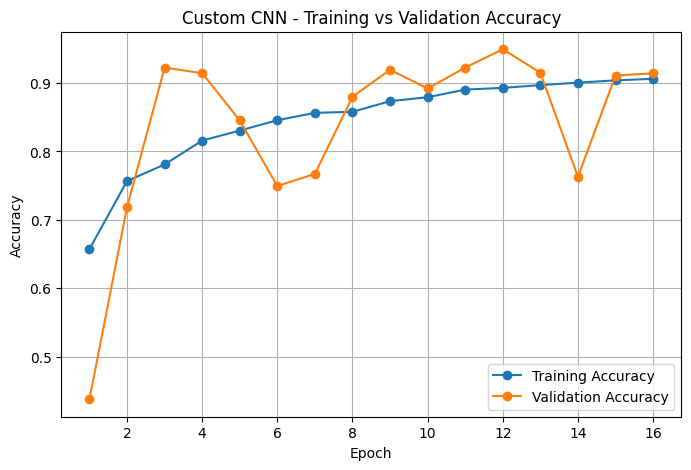

Training graphs saved successfully!


In [67]:
# ==========================================
# PLOT CUSTOM CNN TRAINING HISTORY
# ==========================================

import matplotlib.pyplot as plt
import os

# Create folder to store training graphs
history_path = '/content/drive/MyDrive/Wafer Classification/results/training_history'
os.makedirs(history_path, exist_ok=True)

epochs = range(1, len(history['train_loss']) + 1)

# Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(epochs, history['train_loss'], marker='o',
         label='Training Loss')

plt.plot(epochs, history['val_loss'], marker='o',
         label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Custom CNN - Training vs Validation Loss')
plt.legend()
plt.grid(True)

# Save the loss graph to Google Drive
plt.savefig(
    os.path.join(history_path, 'custom_cnn_loss.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(epochs, history['train_accuracy'], marker='o',
         label='Training Accuracy')

plt.plot(epochs, history['val_accuracy'], marker='o',
         label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Custom CNN - Training vs Validation Accuracy')
plt.legend()
plt.grid(True)

# Save the accuracy graph to Google Drive
plt.savefig(
    os.path.join(history_path, 'custom_cnn_accuracy.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Training graphs saved successfully!")

In [68]:
# ==========================================
# LOAD BEST CUSTOM CNN CHECKPOINT
# ==========================================

# Define the path where the best model was saved
checkpoint_file = (
    '/content/drive/MyDrive/Wafer Classification/'
    'checkpoints/custom_cnn.pth'
)

# Load the saved model weights into our CNN
model.load_state_dict(
    torch.load(checkpoint_file, map_location=device)
)

# Set the model to evaluation mode
model.eval()

print("Best Custom CNN checkpoint loaded successfully!")

Best Custom CNN checkpoint loaded successfully!


In [69]:
# ==========================================
# CUSTOM CNN TESTING
# ==========================================

# Store actual labels and predicted labels
all_predictions = []
all_labels = []

# Set model to evaluation mode
model.eval()

# Disable gradient calculation during testing
with torch.no_grad():

    for images, labels in test_loader:

        # Move images to GPU
        images = images.to(device)

        # Generate predictions
        outputs = model(images)

        # Select the class with the highest score
        predictions = torch.argmax(outputs, dim=1)

        # Store predictions and actual labels
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Testing completed!")

print("Total test samples:", len(all_labels))
print("Total predictions:", len(all_predictions))

Testing completed!
Total test samples: 25855
Total predictions: 25855


In [70]:
# ==========================================
# CLASSIFICATION PERFORMANCE METRICS
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Calculate overall test accuracy
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Custom CNN Test Accuracy: {test_accuracy:.4f}")

# Generate detailed classification report
print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(9)),
    target_names=class_names,
    zero_division=0
))

Custom CNN Test Accuracy: 0.9247

Classification Report:

              precision    recall  f1-score   support

      Center       0.75      0.73      0.74       603
       Donut       0.44      0.94      0.60        83
    Edge-Loc       0.54      0.79      0.64       772
   Edge-Ring       0.93      0.98      0.96      1432
         Loc       0.49      0.43      0.46       576
   Near-full       0.65      1.00      0.79        15
      Random       0.87      0.89      0.88       131
     Scratch       0.19      0.80      0.31       177
        none       0.99      0.95      0.97     22066

    accuracy                           0.92     25855
   macro avg       0.65      0.83      0.70     25855
weighted avg       0.95      0.92      0.93     25855



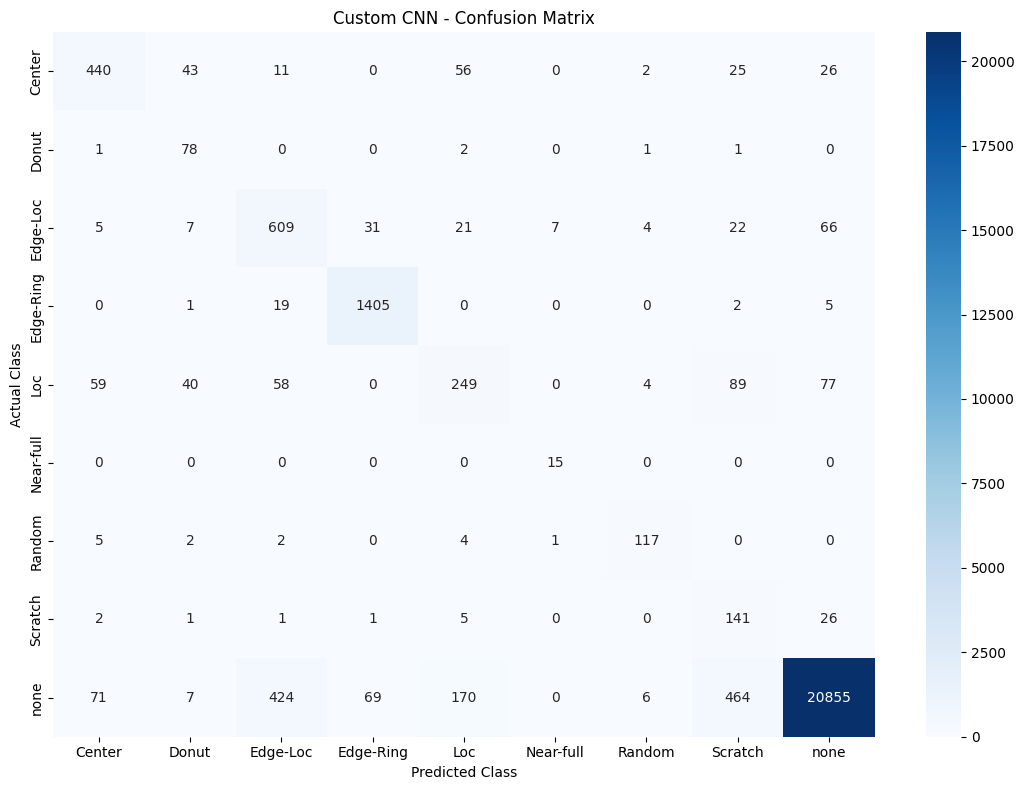

Confusion matrix saved successfully!


In [71]:
# ==========================================
# CONFUSION MATRIX - CUSTOM CNN
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.metrics import confusion_matrix

# Calculate confusion matrix using actual and predicted labels
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(9))
)

# Create figure for confusion matrix
plt.figure(figsize=(11, 8))

# Visualize confusion matrix using a heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

# Add axis labels and title
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Custom CNN - Confusion Matrix')

plt.tight_layout()

# Save confusion matrix in Google Drive
results_path = '/content/drive/MyDrive/Wafer Classification/results'

os.makedirs(results_path, exist_ok=True)

plt.savefig(
    os.path.join(results_path, 'custom_cnn_confusion_matrix.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Confusion matrix saved successfully!")

In [72]:
# ==========================================
# SAVE CUSTOM CNN CLASSIFICATION METRICS
# ==========================================

import pandas as pd

# Generate classification metrics as a dictionary
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(9)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Convert metrics into a DataFrame
report_df = pd.DataFrame(report).transpose()

# Save the classification report
report_df.to_csv(
    os.path.join(results_path, 'custom_cnn_metrics.csv')
)

print("Custom CNN metrics saved successfully!")

Custom CNN metrics saved successfully!


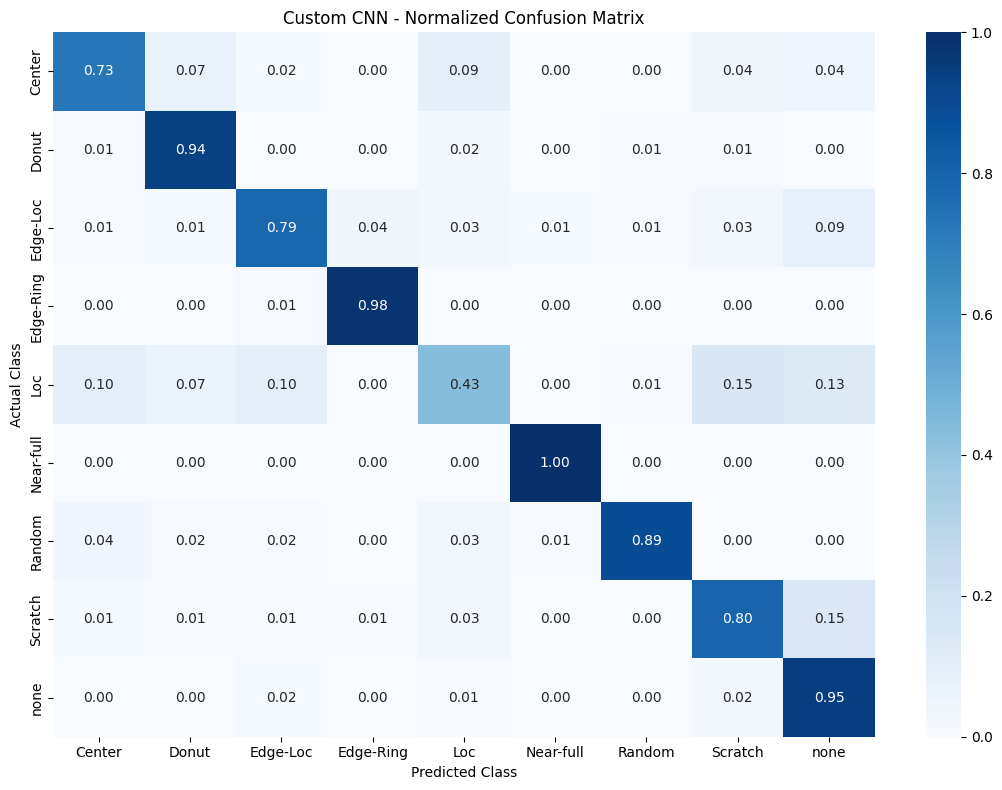

Normalized confusion matrix saved successfully!


In [73]:
# ==========================================
# NORMALIZED CONFUSION MATRIX
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Normalize each row to calculate class-wise percentages
cm_normalized = cm.astype('float') / cm.sum(axis=1, keepdims=True)

# Create a figure
plt.figure(figsize=(11, 8))

# Plot normalized confusion matrix
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

# Add labels and title
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Custom CNN - Normalized Confusion Matrix')

plt.tight_layout()

# Save the normalized confusion matrix
plt.savefig(
    os.path.join(results_path, 'custom_cnn_normalized_confusion_matrix.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Normalized confusion matrix saved successfully!")